# 08.9 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/08-deep-learning/09-augmentation-transfer-learning/solutions.ipynb)

In [1]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # hide TensorFlow's C++ start-up messages
warnings.filterwarnings("ignore")                # hide library deprecation notices
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
keras.utils.set_random_seed(42)                  # same start every run (results still vary slightly by machine)
print("Keras", keras.__version__, "· backend", keras.backend.backend())

import pathlib

def flower_folder():
    """Download the 5-class flower photos once (229 MB) and return the folder."""
    path = keras.utils.get_file(
        "flower_photos", untar=True,
        origin="https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz")
    return next(p.parent for p in pathlib.Path(path).rglob("daisy") if p.is_dir())

def load_flowers(n_train=200, n_val=40, n_test=100, size=160, seed=0):
    """Pick n images per class for train/val/test; return uint8 arrays (small in memory)."""
    root = flower_folder()
    classes = sorted(p.name for p in root.iterdir() if p.is_dir())
    rng = np.random.default_rng(seed)
    parts = {"train": (0, n_train), "val": (n_train, n_train + n_val),
             "test": (n_train + n_val, n_train + n_val + n_test)}
    data = {k: ([], []) for k in parts}
    for label, name in enumerate(classes):
        files = sorted((root / name).glob("*.jpg"))
        rng.shuffle(files)
        for k, (a, b) in parts.items():
            for f in files[a:b]:
                img = keras.utils.load_img(f, target_size=(size, size))
                data[k][0].append(np.asarray(img, dtype="uint8"))
                data[k][1].append(label)
    out = {k: (np.stack(v[0]), np.array(v[1])) for k, v in data.items()}
    return out, classes

data, CLASSES = load_flowers(n_train=200, n_val=40, n_test=100)
(x_train, y_train), (x_val, y_val), (x_test, y_test) = data["train"], data["val"], data["test"]
print("classes:", CLASSES)
print("train", x_train.shape, " val", x_val.shape, " test", x_test.shape,
      f" ({x_train.nbytes / 1e6:.0f} MB as uint8)")

import time

augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),          # up to ±10% of a full turn (±36°)
    layers.RandomZoom(0.1),
], name="augment")

def fit_eval(model, epochs, lr=1e-3):
    """Train on the 1,000 photos, return (test accuracy, seconds)."""
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    start = time.time()
    model.fit(x_train, y_train, validation_data=(x_val, y_val),
              epochs=epochs, batch_size=32, verbose=0)
    return model.evaluate(x_test, y_test, verbose=0)[1], time.time() - start

def small_cnn(with_augmentation):
    steps = [keras.Input((160, 160, 3)), layers.Rescaling(1 / 255)]
    steps += [augment] if with_augmentation else []
    steps += [layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(),
              layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
              layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
              layers.GlobalAveragePooling2D(), layers.Dense(5, activation="softmax")]
    return keras.Sequential(steps)

def transfer_model(base_fn, n_classes=5):
    """Pretrained base (frozen) + augmentation + a new 5-class head."""
    base = base_fn(input_shape=(160, 160, 3), include_top=False, weights="imagenet", pooling="avg")
    base.trainable = False
    inputs = keras.Input((160, 160, 3))
    x = base(augment(inputs), training=False)
    outputs = layers.Dense(n_classes, activation="softmax")(layers.Dropout(0.2)(x))
    return keras.Model(inputs, outputs), base

def trainable(model):
    return sum(int(np.prod(w.shape)) for w in model.trainable_weights)

Keras 3.15.1 · backend tensorflow


classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
train (1000, 160, 160, 3)  val (200, 160, 160, 3)  test (500, 160, 160, 3)  (77 MB as uint8)


## Exercise 1

1,280 × 5 + 5 = **6,405** trainable weights.

In [2]:
keras.utils.set_random_seed(42)
eff_model, eff_base = transfer_model(keras.applications.EfficientNetB0)
print(f"frozen base: {eff_base.count_params():,}   trainable: {trainable(eff_model):,}")

frozen base: 4,049,571   trainable: 6,405


## Exercise 2

In [3]:
keras.utils.set_random_seed(42)
acc_eff, secs_eff = fit_eval(eff_model, epochs=10)
keras.utils.set_random_seed(42)
mob_model, mob_base = transfer_model(keras.applications.MobileNetV3Small)
acc_mob, secs_mob = fit_eval(mob_model, epochs=10)
print(f"MobileNetV3Small: {acc_mob:.3f} in {secs_mob:.0f} s  (base {mob_base.count_params():,} weights)")
print(f"EfficientNetB0:   {acc_eff:.3f} in {secs_eff:.0f} s  (base {eff_base.count_params():,} weights)")

MobileNetV3Small: 0.844 in 10 s  (base 939,120 weights)
EfficientNetB0:   0.878 in 26 s  (base 4,049,571 weights)


EfficientNetB0 is more accurate but about four times larger and slower. On a phone, where memory and battery matter, MobileNetV3Small is the usual choice; on a server tagging supplier uploads overnight, the extra accuracy is worth the compute.

## Exercise 3

 25 photos per class: test accuracy 0.630


 50 photos per class: test accuracy 0.740


100 photos per class: test accuracy 0.816


200 photos per class: test accuracy 0.844


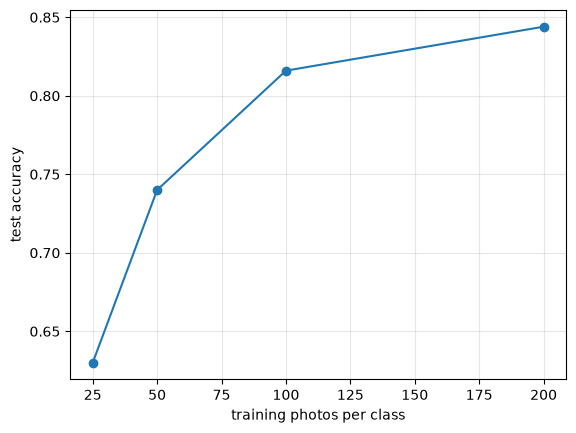

In [4]:
sizes, accs = [25, 50, 100, 200], []
for n in sizes:
    keep = np.concatenate([np.where(y_train == c)[0][:n] for c in range(5)])
    keras.utils.set_random_seed(42)
    m, _ = transfer_model(keras.applications.MobileNetV3Small)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(x_train[keep], y_train[keep], epochs=10, batch_size=32, verbose=0)
    accs.append(m.evaluate(x_test, y_test, verbose=0)[1])
    print(f"{n:>3} photos per class: test accuracy {accs[-1]:.3f}")
plt.plot(sizes, accs, marker="o"); plt.xlabel("training photos per class"); plt.ylabel("test accuracy")
plt.grid(alpha=.3); plt.show()

Transfer learning is useful even with 25 photos per class, and the curve flattens: each doubling of data buys less. That tells ShopWave how much labelling effort a new category needs.

## Exercise 4

In [5]:
def transfer_no_aug():
    base = keras.applications.MobileNetV3Small(input_shape=(160, 160, 3), include_top=False,
                                               weights="imagenet", pooling="avg")
    base.trainable = False
    inputs = keras.Input((160, 160, 3))
    outputs = layers.Dense(5, activation="softmax")(layers.Dropout(0.2)(base(inputs, training=False)))
    return keras.Model(inputs, outputs)

keras.utils.set_random_seed(42)
acc, secs = fit_eval(transfer_no_aug(), epochs=10)
print(f"frozen MobileNetV3Small without augmentation: {acc:.3f}")

frozen MobileNetV3Small without augmentation: 0.848


Compare with the lesson's frozen model with augmentation. With a strong pretrained base the difference is small (a point or two either way between runs): the base already knows that a flipped flower is the same flower. Augmentation matters most when training from scratch or fine-tuning many layers.